# Quantum Metal 51 — four-qubit chip: a ring of TransmonPocketCLs with charge lines and coupled-pad readouts (Quantcore PDK rebuild)

**What the chip is.** Qiskit Metal `docs/circuit-examples/F.Small-quantum-chips/51-Four_qubit_chip.ipynb` (the same
layout, cell for cell, as `docs/tut/2-From-components-to-chip/2.21-Design-a-4-qubit-full-chip.ipynb`), © 2017 IBM
and contributors, Apache-2.0 (<https://github.com/qiskit-community/qiskit-metal>); spec
`docs/designs/metal/51_four_qubit_chip.md`; the id is prefixed `m` (ids do not start with a digit). We distribute the
rebuild under GPL-3.0. Four `TransmonPocketCL`s in a diamond (Q1 / Q3 at (±2.42, 0.069) mm, Q2 / Q4 at
(0, ∓0.858) mm) are joined by a ring of four 9 mm λ/2 buses; each qubit has an 8.6 mm λ/2 readout to a
`LaunchpadWirebondCoupled` and a charge line from a corner `LaunchpadWirebond` into its `Charge_Line` pin. 10/6 µm
CPW, fillet 99.99 µm.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
Metal components are drawn through the `metal:<Class>` wrapper with the tutorial's own options; the chip, the stack,
the junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal (51 / 2.21) | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` 9 × 6.5 mm centred on (0, 0) | the same 9 × 6.5 mm box (it does not fit the 7.5 mm die), shifted by (+4.5, +3.25) mm, with the QCT die frame |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | 8 pads, outer edge 178–230 µm from the chip edge | the same pads, moved to **100 µm** (`frame.pad_edge`) from the die edge (PDK pad rule) |
| junctions | `FakeJunction_01` GDS cell, no inductance stated | Quantcore Nb/AlOx/Nb trilayer junction, PDK nominal 0.5 × 0.6 µm (R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF) |
| cheese | notebook 51 never exports a GDS (its twin 2.21 does) | the PDK band (chip `cheese: "auto"`) |
| buses / readouts | `RouteMeander` 9.0 / 8.6 mm | waypoint serpentines with Metal's 200 µm run pitch, the same total lengths |
| charge lines | `RouteAnchors`, 3277 / 4866 / 3415 / 4866 µm | the same anchors; each line ≈ 78 µm longer because its pad moved to the edge |
| placement | as drawn | content centred in the die (already centred: the pads span the die) |

**Kept exactly:** the qubits with the tutorial's options (connection pads `a`/`b`/`c` with pad widths 70 / 125 /
110 µm and `cpw_extend` 50 µm, `cl_off_center` −50 µm, `cl_pocket_edge` 180, the 69 µm off-centre shift of Q1 /
Q3), the launchpads (`lead_length` 0 / 30 µm), every position along its edge, every route's end pins and the
total lengths of the buses (9000 µm) and readouts (8600 µm).

**Simplified:** Metal's `RouteMeander`s (with ±414 … ±552 µm asymmetry that pushes each bus's meander row away from
the ring centre) are laid out as waypoint serpentines with Metal's 200 µm run pitch, sized to the same total length;
the rows sit where Metal's do (beside the north and south qubits), the readouts fill the same corners. Moving the
readout pads 88–130 µm outward lengthens the straight lead to each pad, so each readout serpentine's runs are
made a quarter of that shorter (step 6) and the readouts keep 8600 µm. The charge lines' first corner beside Q1 /
Q3 moves 83 µm outward (Metal's 120 µm lead is shorter than two 100 µm fillets).

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the die, the bond pads, the readout pads, the qubits, the readout
resonators, the coupling buses, the charge lines, and then the whole chip. Then the same steps as the Flow strip of
the Quantcore KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to
HFSS, the component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM
against the LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in one cell, with its outputs) is kept as `m51_four_qubit_chip.v1.ipynb`; both save the same
`m51_four_qubit_chip.json`.

## Setup

The imports, the output folder, the Metal → Designer coordinate helpers and the switches. `LIVE`: with KLayout open
(the default) every change below is pushed to the KLayout window as you run it; with `QCC_LIVE=0` the notebook builds
headless and only writes files. `_common` holds the helpers the design notebooks share (tables, snapshots, the PDK
placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement, FEM and feedback helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
X0, Y0 = 4500, 3250                              # Metal's 9 × 6.5 mm chip is centred on (0, 0)
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm
R = 99.99                                        # Metal fillet
MX = lambda pts: [(2 * X0 - x, y) for x, y in pts]              # mirror x → 9000 − x
PM = lambda pts, yc=Y0: [(2 * X0 - x, 2 * yc - y) for x, y in pts]   # point mirror through (4500, yc)


def vsnake(xs, ends, y0):
    """Serpentine of vertical runs: from (xs[0], y0) run to ends[0], step to xs[1], run to ends[1], …"""
    pts = [(xs[0], y0)]
    for i, x in enumerate(xs):
        if i:
            pts.append((x, ends[i - 1]))
        pts.append((x, ends[i]))
    return pts


def hsnake(ys, ends, x0):
    """Serpentine of horizontal runs (the transpose of ``vsnake``)."""
    return [(x, y) for y, x in vsnake(ys, ends, x0)]

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 9 × 6.5 mm box gets the QCT frame; the eight launchpads go 100 µm from their edges; the four qubits get the PDK nominal trilayer junction; the free ground gets the PDK cheese band.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). In the Designer a route always joins two ports, so a resonator is
drawn once both of its ends exist: the readout *pads* come before the qubits (segment 3), the readout *resonators*
after them (segment 5).

| segment | what is placed here |
|---|---|
| 1 | the 9 × 6.5 mm die with the QCT frame |
| 2 | the four corner bond pads for the charge lines |
| 3 | the readout: four coupled launchpads (this chip has no feedline) |
| 4 | the four qubits with their trilayer junctions |
| 5 | the four λ/2 readout resonators |
| 6 | the coupling: a ring of four λ/2 buses |
| 7 | the control routing: four charge lines |
| 8 | the whole chip: sim groups, centring, save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm); the PDK draws the **QCT frame** on it: L
dicing markers in the four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary
(100/0) and the device ID `name_chip` on a free edge (optional: no free edge, no ID). Metal centres its chip on
(0, 0); our box starts at (0, 0), so every Metal position goes through `P(x, y)` = Metal + half the chip.

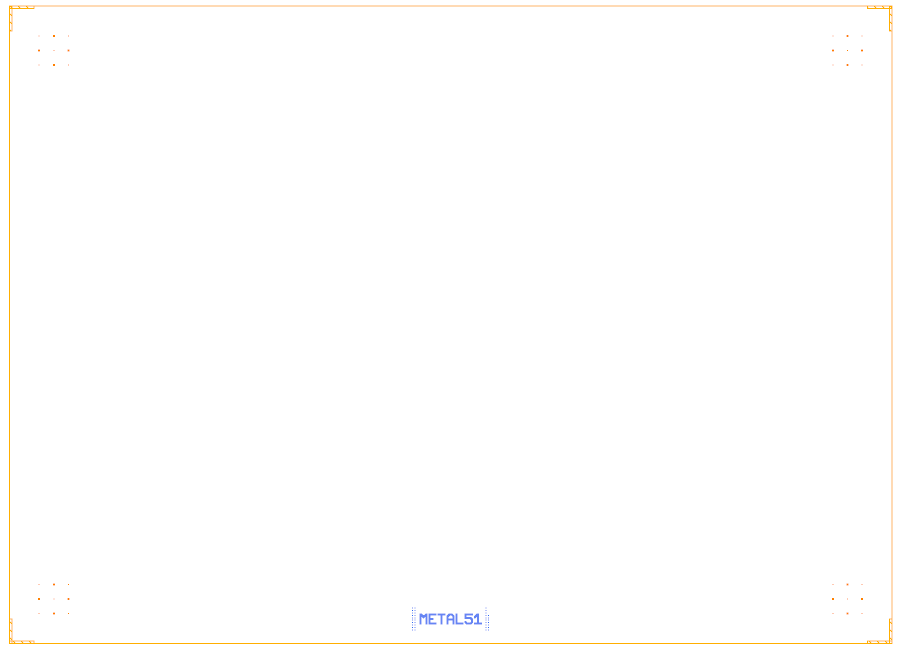

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/m51_four_qubit_chip_s1_die.png')

In [5]:
d = Designer("m51_four_qubit_chip", box=(0, 0, 9000, 6500), chip={"name_chip": "Metal51"}, live=LIVE)
layout_step(d, OUT / "m51_four_qubit_chip_s1_die.png", size=(900, 650), width=450)

## Design 2 · Bond pads: the four charge-line pads

The four `LaunchpadWirebond`s (`P<k>_C`, `lead_length` 0) sit in the corners; each will feed one qubit's charge line
(segment 7). In the source their outer etch edges sit 178–230 µm in from the chip edge. In the Quantcore PDK the outer
etch edge of every bond pad sits **`frame.pad_edge` = 100 µm from the die edge**: `edge="n"` / `"s"` slides each pad
perpendicular to that edge until it is there, keeping its position along the edge.

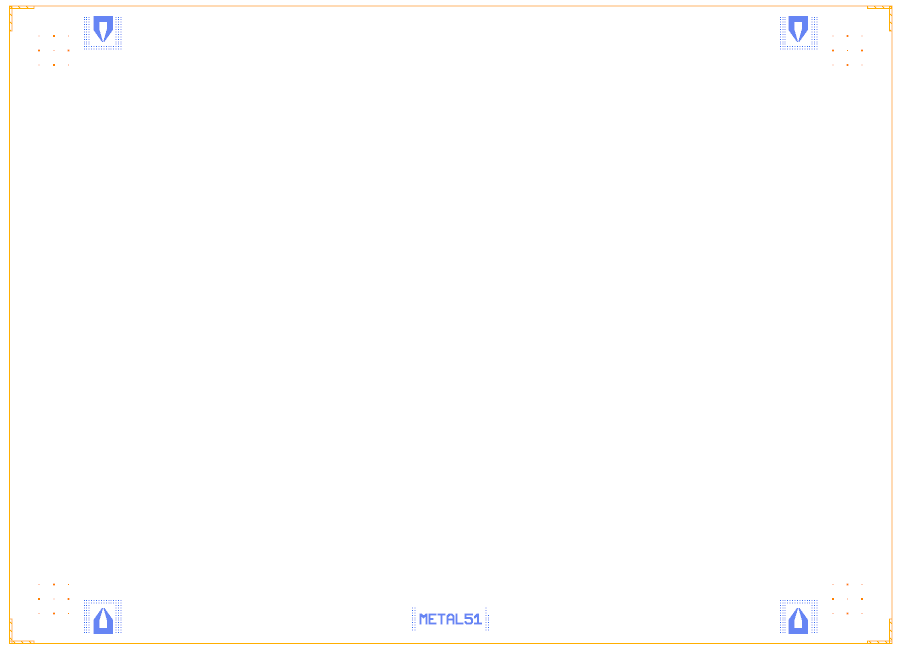

**On the chip so far:** 4 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 4 component(s) `P1_C`, `P2_C`, `P3_C`, `P4_C`.

WindowsPath('examples/designs/metal/m51_four_qubit_chip_s2_pads.png')

In [6]:
with d.batch():
    pc = {k: d.add(f"P{k}_C", "metal:LaunchpadWirebond", at=P(x, y), rot=r, lead_length=0, edge=e)
          for k, x, y, r, e in ((1, 3545, 2812, 270, "n"), (2, 3545, -2812, 90, "s"), (3, -3545, -2812, 90, "s"),
                                (4, -3545, 2812, 270, "n"))}
layout_step(d, OUT / "m51_four_qubit_chip_s2_pads.png", size=(900, 650), width=450)

## Design 3 · Readout: the four coupled launchpads

This chip has no shared feedline: each qubit is read out through its own λ/2 resonator into its own pad. The pad is
a `LaunchpadWirebondCoupled` (`P<k>_Q`, `lead_length` 30 µm): a bond pad with a series capacitor at its `tie`, so the
resonator (segment 5) ends on a capacitor, not on the 50 Ω line. The same pad rule puts them 100 µm from the east,
south, west and north edges. The table measures every pad's distance on the built layout; the picture zooms on the
east pad `P1_Q`.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| P1_C | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| P2_C | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| P3_C | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| P4_C | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| P1_Q | `metal:LaunchpadWirebondCoupled` | e | 100.0 | ✓ |
| P2_Q | `metal:LaunchpadWirebondCoupled` | s | 100.0 | ✓ |
| P3_Q | `metal:LaunchpadWirebondCoupled` | w | 100.0 | ✓ |
| P4_Q | `metal:LaunchpadWirebondCoupled` | n | 100.0 | ✓ |

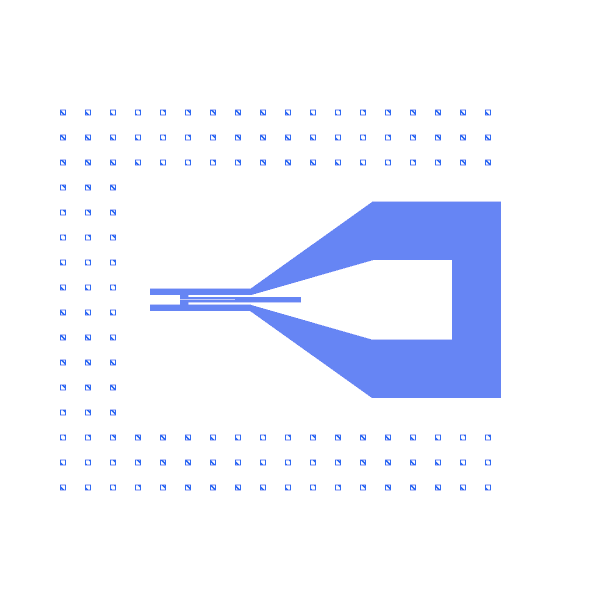

**On the chip so far:** 8 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 4 component(s) `P1_Q`, `P2_Q`, `P3_Q`, `P4_Q`.

WindowsPath('examples/designs/metal/m51_four_qubit_chip_s3_readout_pads.png')

In [7]:
with d.batch():
    pq = {k: d.add(f"P{k}_Q", "metal:LaunchpadWirebondCoupled", at=P(x, y), rot=r, lead_length=30, edge=e)
          for k, x, y, r, e in ((1, 4020, 0, 180, "e"), (2, -990, -2812, 90, "s"), (3, -4020, 0, 0, "w"),
                                (4, 990, 2812, 270, "n"))}
rebuild(d)
display(Markdown(pads_md(d)))
px, py = port_xy(d, "P1_Q.tie")
layout_step(d, OUT / "m51_four_qubit_chip_s3_readout_pads.png", box=(8400, py - 300, 9000, py + 300), size=(600, 600),
            width=300)

## Design 4 · Qubit placement: four pocket transmons

**The qubits.** `metal:TransmonPocketCL` is Metal's pocket transmon with a charge-line pin (`Charge_Line`), drawn by
the wrapper with the tutorial's options: three connection pads `a` (the readout, lower right), `b` and `c` (the bus
pads, lower and upper left; pad widths 70 / 125 / 110 µm, `cpw_extend` 50 µm), the charge line 50 µm off-centre at
pocket edge 180°. Q2 / Q4 are rotated 270° / 90°, Q3 by 180°, so the diamond's pads face each other.

**The junction.** With `junction_type` unset the wrapper already draws the Quantcore trilayer junction;
`trilayer_junction` makes it explicit and returns the drawn junction's L_J and C_J for the LOM and the FEM junction
port (`junction=`). The source's `FakeJunction_01` states no value, so every qubit gets the PDK nominal junction
(fingers 0.5 × 0.6 µm on 2/0 + 4/0, a 50/0 spacer with the 51–53/0 dose gradient, R_n 45 kΩ, L_J 6.73 nH,
C_J 15 fF).

Each component has named **ports** (Metal's pins): routes connect to them, and the LOM maps each to a circuit node.

The first picture is the chip so far; the second zooms on Q1 (its three connection pads and the charge-line pin).

junction: {'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}
Q1 ports: ['Charge_Line', 'a', 'b', 'c', 'squid_a', 'squid_b']


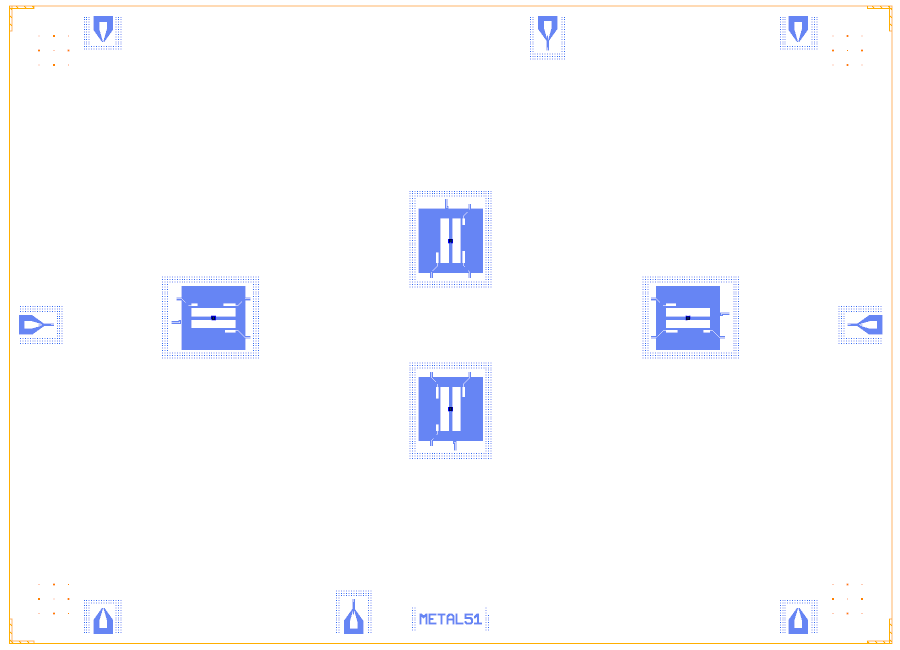

**On the chip so far:** 8 pads · 4 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 4 component(s) `Q1`, `Q2`, `Q3`, `Q4`.

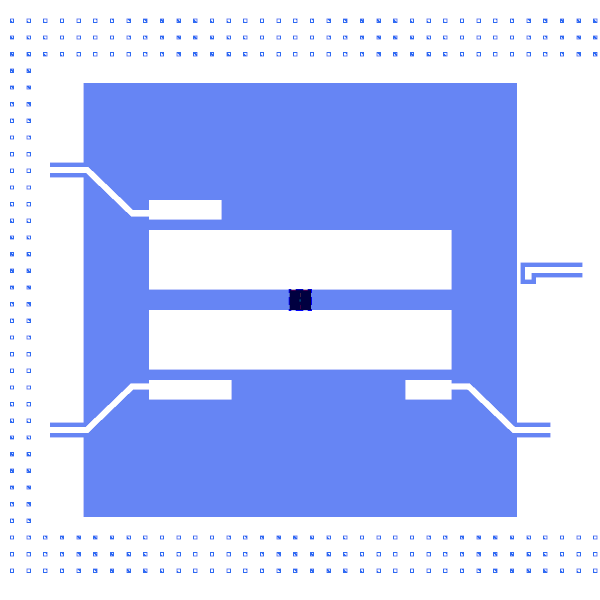

WindowsPath('examples/designs/metal/m51_four_qubit_chip_step_parts.png')

In [8]:
# Quantcore trilayer junction on the PDK rule (Nb Δ 1.4 meV): nominal fingers 0.5 × 0.6 µm → R_n 45 kΩ,
# L_J 6.73 nH, C_J 15 fF. JJ_PARAMS = {"junction_type": "Quantcore Junction"}; JUNCTION = its {Lj_nH, Cj_fF}
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonPocket")
print("junction:", JJ_PARAMS, JUNCTION)
with d.batch():
    tm = dict(cl_off_center=-50, cl_pocket_edge=180, junction=JUNCTION, **JJ_PARAMS,
              connection_pads={"a": {"loc_W": 1, "loc_H": -1, "pad_width": 70, "cpw_extend": 50},
                               "b": {"loc_W": -1, "loc_H": -1, "pad_width": 125, "cpw_extend": 50},
                               "c": {"loc_W": -1, "loc_H": 1, "pad_width": 110, "cpw_extend": 50}})
    offset_tm = 69                                   # the source's off-centre shift of Q1 / Q3
    q = {k: d.add(f"Q{k}", "metal:TransmonPocketCL", at=P(x, y), rot=r, **tm)
         for k, x, y, r in ((1, 2420, offset_tm, 0), (2, 0, -857.6, 270), (3, -2420, offset_tm, 180),
                            (4, 0, 857.6, 90))}
print("Q1 ports:", sorted(q[1].ports))
layout_step(d, OUT / "m51_four_qubit_chip_s4_qubits.png", size=(900, 650), width=450)
qx, qy = P(2420, offset_tm)
snap(d, OUT / "m51_four_qubit_chip_step_parts.png", box=(qx - 450, qy - 450, qx + 450, qy + 450), size=(600, 600),
     width=300)

## Design 5 · Readout: the four λ/2 readout resonators

Each qubit's pad `a` gets an 8.6 mm λ/2 resonator (`ol1`–`ol4`, `meander=8600`) to its coupled launchpad: four-run
serpentines in the chip's corners, at Metal's 200 µm run pitch. The pads moved 130 µm (east / west) and 88 µm
(north / south) outward in segments 2–3 (to the 100 µm PDK edge), so the straight lead to each pad is that much
longer; each serpentine has four runs ending at the same extent, so moving that extent by a quarter of the pad move
keeps the total at 8600 µm (`YL1`, `YH3`, `XL2` below: 1171.42, 5432.08 and 2309.77 µm; Metal's were 1139, 5464.5
and 2288 µm).

**No zigzag.** A `meander` route is its waypoint path plus whatever length is left over. The router puts a
leftover within 0.01 µm nowhere (the path is the length), a small one into the free corners (their bend radius a few
nm smaller), and only a real one into a KQC `Meander` on the longest free straight, with no more turns than keep it
at least r wide. (Before 2026-11-18 a few µm left over came out as a shallow slanted zigzag along the whole straight.)
The extents above are solved so the waypoint path already is the full length.

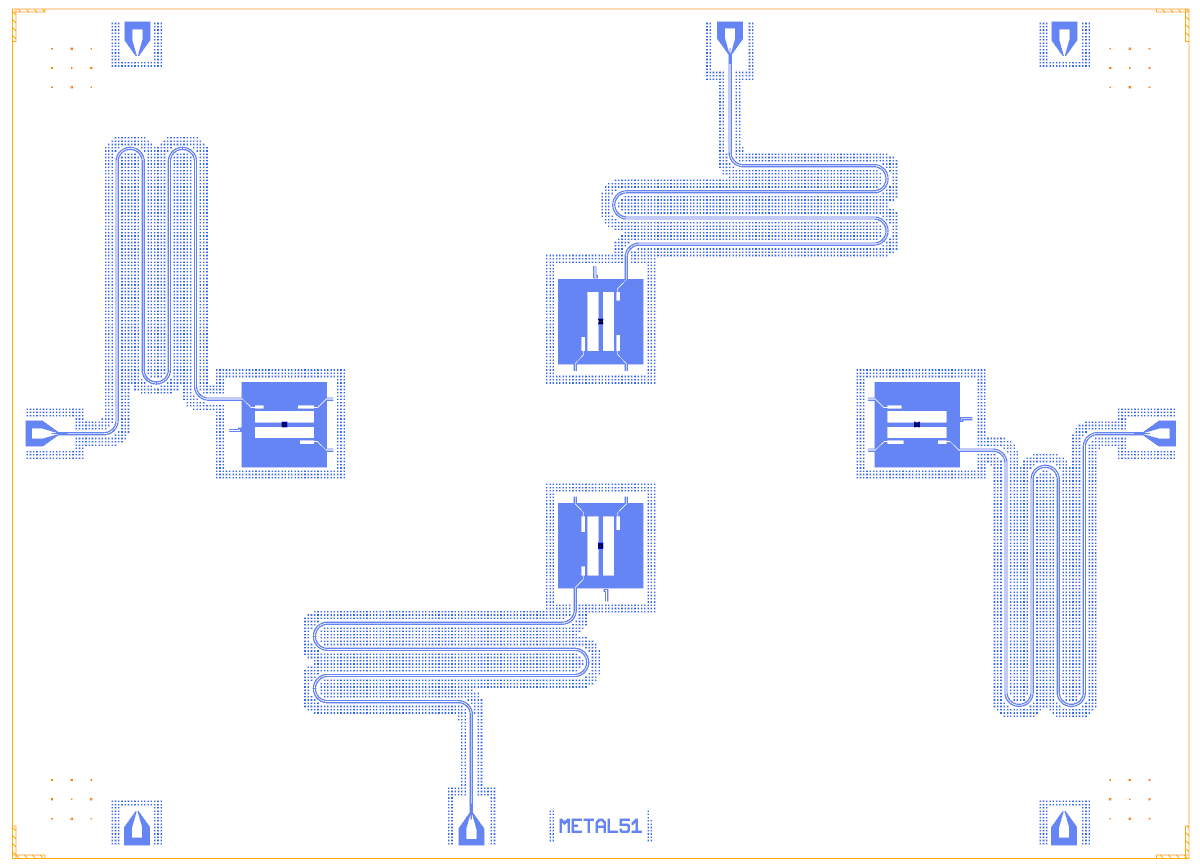

**On the chip so far:** 8 pads · 4 qubits · 0 other components · 4 routes · 0 declared couplings. **This step added** 4 route(s) `ol1`, `ol2`, `ol3`, `ol4`.

WindowsPath('examples/designs/metal/m51_four_qubit_chip_s5_readouts.png')

In [9]:
# serpentine extents: each readout's waypoint path is its full length to < 0.01 µm, with the pads at the PDK edge
YL1, YH3, XL2 = 1171.4175, 5432.0825, 2309.7675  # readout runs (Metal 1139, 5464.5, 2288: the pads moved outward)
with d.batch():
    o1 = vsnake([7600, 7800, 8000, 8200], [YL1, 3000, YL1, 3250], 3124)
    o3 = vsnake([1400, 1200, 1000, 800], [YH3, 3638, YH3, 3250], 3514)
    o2 = [(4305, 1800)] + hsnake([1800, 1600, 1400, 1200], [XL2, 4400, XL2, 3510], 4305)[1:]
    d.route("ol1", q[1].a, pq[1].tie, meander=8600, r=R, nodes=o1)
    d.route("ol2", q[2].a, pq[2].tie, meander=8600, r=R, nodes=o2)
    d.route("ol3", q[3].a, pq[3].tie, meander=8600, r=R, nodes=o3)
    d.route("ol4", q[4].a, pq[4].tie, meander=8600, r=R, nodes=PM(o2))
layout_step(d, OUT / "m51_four_qubit_chip_s5_readouts.png", size=(1200, 867), width=480)

## Design 6 · Coupling: a ring of four λ/2 buses

The qubits couple to each other only through four 9 mm λ/2 buses (`cpw1`–`cpw4`, `meander=9000`), each from a `b` or
`c` pad of one qubit to the facing pad of its neighbour, so the four buses close a ring. They are serpentines of eight
runs at Metal's 200 µm pitch beside the north and south qubits, like Metal's offset meander rows; the waypoints set
the path, and the fixed length makes the router check it is 9000 µm (`YH`, `YL`: 4407.62 and 2109.63 µm; Metal's
4407.5 and 2109.7).

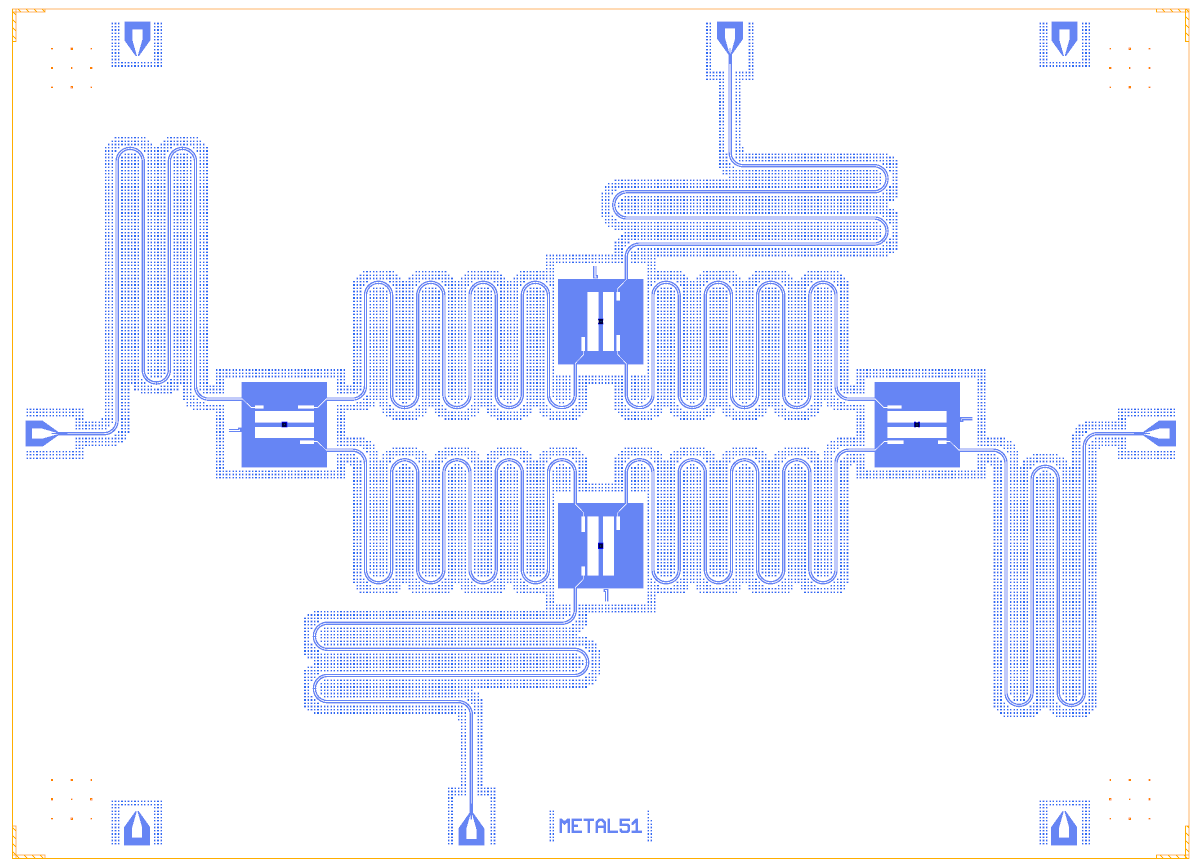

**On the chip so far:** 8 pads · 4 qubits · 0 other components · 8 routes · 0 declared couplings. **This step added** 4 route(s) `cpw1`, `cpw2`, `cpw3`, `cpw4`.

WindowsPath('examples/designs/metal/m51_four_qubit_chip_s6_buses.png')

In [10]:
YH, YL = 4407.6213, 2109.6288                    # bus runs (Metal: 4407.5, 2109.7)
with d.batch():
    xs = [6300 - 200 * i for i in range(8)]
    n1 = vsnake(xs, [YH, 3450] * 4, 3514) + [(4695, 3450)]          # Q1.c → Q4.b
    n4 = vsnake(xs, [YL, 3050] * 4, 3124) + [(4695, 3050)]          # Q1.b → Q2.c
    d.route("cpw1", q[1].c, q[4].b, meander=9000, r=R, nodes=n1)
    d.route("cpw2", q[3].b, q[4].c, meander=9000, r=R, nodes=MX(n1))
    d.route("cpw3", q[3].c, q[2].b, meander=9000, r=R, nodes=MX(n4))
    d.route("cpw4", q[1].b, q[2].c, meander=9000, r=R, nodes=n4)
layout_step(d, OUT / "m51_four_qubit_chip_s6_buses.png", size=(1200, 867), width=480)

## Design 7 · Routing: the four charge lines

Each qubit's `Charge_Line` pin (50 µm off-centre at pocket edge 180°) is wired to its corner pad from segment 2
(`line_cl1`–`line_cl4`), through Metal's `RouteAnchors` corner points. They end on the corner pads, so each is the
pad move (78 µm) longer than Metal's; the first corner beside Q1 / Q3 moves 83 µm outward (Metal's 120 µm lead is
shorter than two 100 µm fillets).

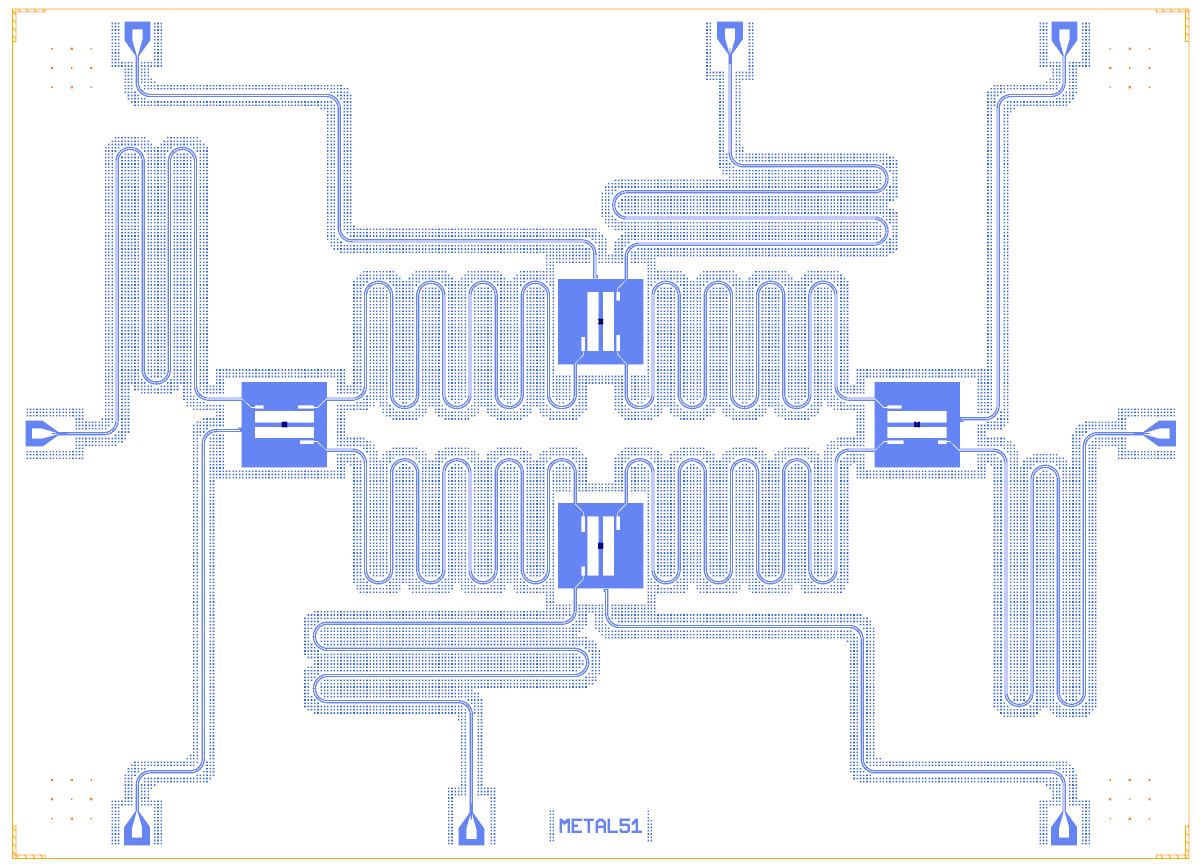

**On the chip so far:** 8 pads · 4 qubits · 0 other components · 12 routes · 0 declared couplings. **This step added** 4 route(s) `line_cl1`, `line_cl2`, `line_cl3`, `line_cl4`.

WindowsPath('examples/designs/metal/m51_four_qubit_chip_s7_charge_lines.png')

In [11]:
with d.batch():
    d.route("line_cl1", q[1].Charge_Line, pc[1].tie, r=R, nodes=[(7540, 3364), (7540, 5837), (8045, 5837)])
    d.route("line_cl2", q[2].Charge_Line, pc[2].tie, r=R, nodes=[(4545, 1775), (6500, 1775), (6500, 663), (8045, 663)])
    d.route("line_cl3", q[3].Charge_Line, pc[3].tie, r=R, nodes=[(1460, 3274), (1460, 663), (955, 663)])
    d.route("line_cl4", q[4].Charge_Line, pc[4].tie, r=R,
            nodes=PM([(4545, 1775), (6500, 1775), (6500, 663), (8045, 663)]))
layout_step(d, OUT / "m51_four_qubit_chip_s7_charge_lines.png", size=(1200, 867), width=480)

## Design 8 · The whole chip: sim groups, centring, save

**Sim groups** say what a FEM job cuts out of the chip: the ring (the four qubits with the four buses, Q3D) and Q1 /
Q3 with their readout and launchpad (Q3D and eigenmode). The margins are chosen so that each box cuts every other line
once; a box round the Q2 or Q4 readout would hold bus runs, so those two are not exported.

**Centring.** The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of
everything placed (components and routes) and shifts the design so its centre is the die centre (pads keep their
100 µm: they slide back to the edge along it). Here the pads span the die in both directions and the source is
symmetric, so nothing moves.

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's): the segments above changed how the chip is built, not the chip, so it should say *same design*. The
file keeps the previous key order (the routes were added in another order here), so `git diff` stays empty.

content shifted by (0.0, 0.0) µm


**Same design as before:** `examples/designs/metal/m51_four_qubit_chip.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer m51_four_qubit_chip: 12 instances, 12 routes, live=False> → examples\designs\metal\m51_four_qubit_chip.json
route lengths (µm): {'ol1': 8600.0, 'ol2': 8600.0, 'ol3': 8600.0, 'ol4': 8600.0, 'cpw1': 9000.0, 'cpw2': 9000.0, 'cpw3': 9000.0, 'cpw4': 9000.0, 'line_cl1': 3355.3, 'line_cl2': 4943.7, 'line_cl3': 3493.3, 'line_cl4': 4943.7}


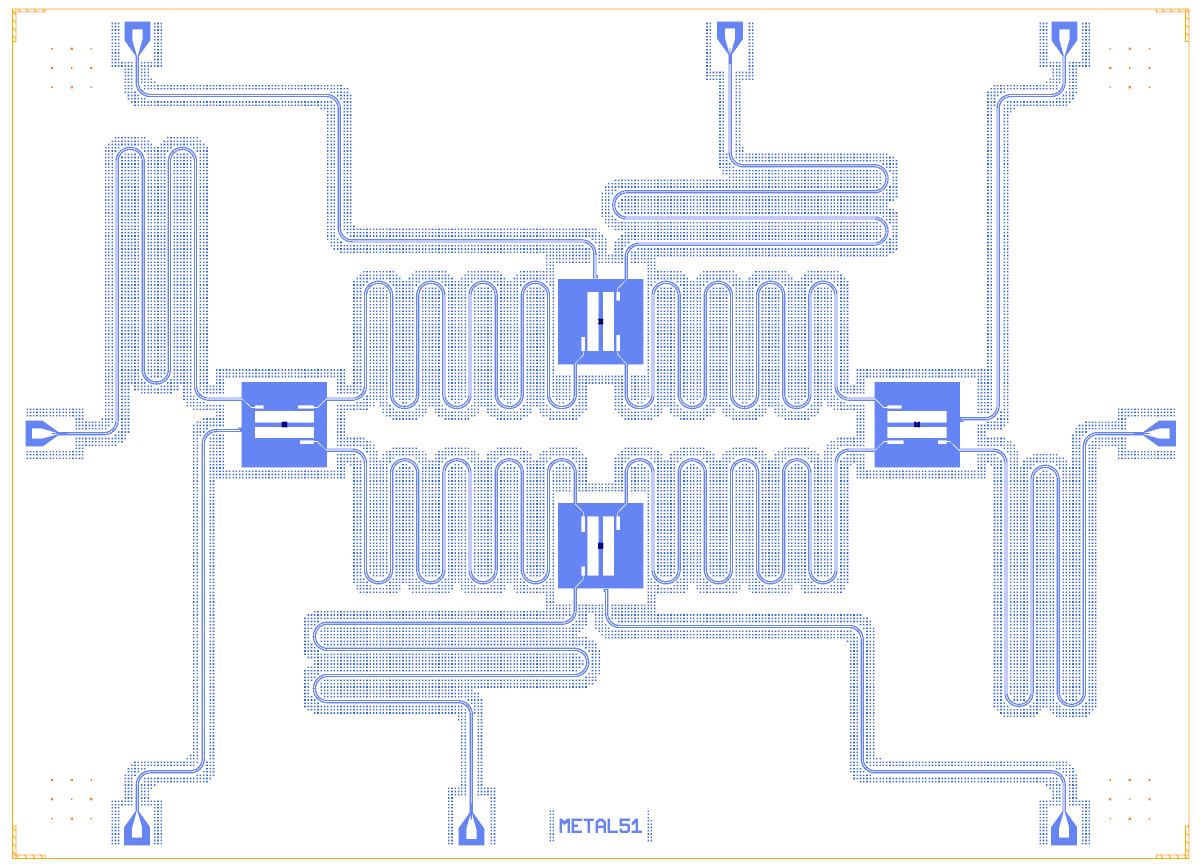

**On the chip so far:** 8 pads · 4 qubits · 0 other components · 12 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/m51_four_qubit_chip_step_routes.png')

In [12]:
d.sim_group("ring", ["Q1", "Q2", "Q3", "Q4", "cpw1", "cpw2", "cpw3", "cpw4"], margin_um=150, analyses=["q3d_cmatrix"])
for k in (1, 3):
    d.sim_group(f"Q{k}_read", [f"Q{k}", f"ol{k}", f"P{k}_Q"], margin_um=30, analyses=["q3d_cmatrix", "eigenmode_epr"])
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
DESIGN, same = save_design(d, OUT / "m51_four_qubit_chip.json")
display(Markdown(same))
print(d, "→", DESIGN)
print("route lengths (µm):", {k: round(v, 1) for k, v in d.result.route_lengths().items()})
layout_step(d, OUT / "m51_four_qubit_chip_step_routes.png", size=(1200, 867), width=480)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here (from the v1 run): **no errors**, eight `dangling_port` warnings (`Q<k>.squid_a` / `squid_b`, the junction's
attachment points: the qubit cell draws the junction itself, nothing is routed there) and **no PDK design
warnings** (the pads are at 100 µm, the nominal junction is in the R_n window, the design sets no targets).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [ ]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: each `TransmonPocketCL` gives two floating pad nodes with the
junction between them, a node per connection pad, and the `Charge_Line` as a drive port; each bus between two pads
and each readout between a pad and a coupled launchpad (series C to its 50 Ω port) is a λ/2 `TLres`; the charge
lines end on their 50 Ω pads. The port map shows which node each of Q1's ports landed on.

In [ ]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q1.", "P1_"))})

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

QuCat solves each sub-circuit's normal modes (frequency, κ through the 50 Ω ports, anharmonicity); QuTiP diagonalises
the dressed Hamiltonian for f_q, α, f_r and χ. First each qubit with its readout, launchpad and charge line; then
each ring bus with the two qubits it joins (static ZZ).

With the PDK junction (6.73 nH, 15 fF; numbers from the v1 run) the four identical qubits sit near 7.1 GHz, above the ≈ 6.6 GHz λ/2 buses and
≈ 0.1 GHz above their 7.0 GHz readouts (the pre-rebuild build assumed 10 nH and had them at 6.3 GHz). Identical
qubits on one bus hybridise (the per-pair ZZ is then "hybridised", not defined). The source states no targets.

In [ ]:
read = {f"Q{k}+ol{k}": [f"Q{k}", f"ol{k}", f"P{k}_Q", f"line_cl{k}", f"P{k}_C"] for k in (1, 2, 3, 4)}
results = simulate_groups(d, read)
display(Markdown(groups_md(results)))
ring = {"Q1+cpw1+Q4": ["Q1", "cpw1", "Q4"], "Q3+cpw2+Q4": ["Q3", "cpw2", "Q4"],
        "Q3+cpw3+Q2": ["Q3", "cpw3", "Q2"], "Q1+cpw4+Q2": ["Q1", "cpw4", "Q2"]}
coupled = simulate_groups(d, ring, max_modes=3)
for g, res in coupled.items():
    display(Markdown(f"**{g}, QuCat normal modes:**\n\n" + modes_md(res)))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(coupled)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each simulated group (QuCat; circles are qubits, squares
resonators; filled markers are the QuTiP dressed values), (b) the dispersive shift |χ| of each readout. Here (from the
v1 run) the qubit and readout markers of each `Q+ol` group sit ≈ 0.1 GHz apart, which is why χ is large.

In [ ]:
plot_lom({**results, **coupled}, OUT / "m51_four_qubit_chip_lom.png", title="m51: LOM per sub-circuit")

## LOM 3 · One geometry change, by hand

Before the FEM, a hand-made design step: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property — here Q1's readout pad `a`, 70 → 120 µm wide — rebuild, re-run the LOM of Q1 with its
readout and compare. A wider pad couples Q1 more strongly to its readout and loads both: f_r and f_q drop and |χ|
grows. (With the PDK junction Q1 sits only ≈ 110 MHz above its readout, so χ here is near-resonant, not a dispersive
shift: the values are the source's geometry with the PDK junction, flagged, not retuned.)

In [ ]:
d2 = design_copy(DESIGN)
pads = dict(d2.data["instances"]["Q1"]["params"]["connection_pads"])
pads["a"] = {**pads["a"], "pad_width": 120}      # 70 → 120 µm
d2["Q1"].set(connection_pads=pads)
group = {"Q1+ol1": read["Q1+ol1"]}
after = simulate_groups(d2, group)
display(Markdown(params_delta_md({"Q1+ol1": results["Q1+ol1"]}, after)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/metal/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

Q3D C-matrix jobs for every sim group (`ring`: the four qubits with the four buses; `Q1_read`, `Q3_read`: the
qubit with its readout and launchpad) and eigenmode / EPR jobs for `Q1_read` and `Q3_read` (the lines leaving the
box end in 50 Ω, so the mode Q gives κ).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/metal/fem/: solved results are kept here
jobs = export_sims(DESIGN)                       # Q3D C-matrix: one job per sim group
jobs_eig = export_sims(DESIGN, ["Q1_read", "Q3_read"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrices

The capacitance of each component group: `Q1_read` and `Q3_read` (the qubit's two pads, its connection pads, the
readout stub and the launchpad as named nets) and `ring` (the four qubits with the four buses). Each net is named
after its LOM node, so the matrix goes straight into the circuit (Results 3). `fem_stage` solves each job with
`RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The same `Q1_read` / `Q3_read` boxes in HFSS eigenmode: the junction is a lumped L_J ‖ C_J sheet, every line the box
cuts and the launchpad end in 50 Ω, so each mode's Q gives κ. pyEPR (run inside qcc's own AEDT, never KQC's
`run_pyepr_t1_estimate.py`) turns the junction's energy participation p_J into dressed frequencies, α and χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box. The library cannot hand the solved eigenmode **mesh**
itself to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the same sim
group and box, the eigenmode job's mesh seeds (the gap and junction-island seeds that resolved the modes), the
adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before the eigenmode is solved) and a fast
sweep around it.

This chip's readouts end on a pad, not on a feedline: the job's ports are the launchpad and the lines the box cuts,
so the S21 notch fit (made for hangers) may find no notch; then κ comes from the eigenmode Q (Results 2).

In [ ]:
f_r1 = results["Q1+ol1"].params.get("ol1.f_GHz")            # the LOM's readout frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "Q1_read", jobs_eig["Q1_read"][0], keep_eig["Q1_read"], f_guess=f_r1)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["Q1_read"]:
    display(Markdown(driven_md(keep_drv["Q1_read"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit; ≈ 0: the readout), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
lom_f = {"Q1": results["Q1+ol1"].params.get("Q1.f_q_GHz"), "ol1": f_r1,
         "Q3": results["Q3+ol3"].params.get("Q3.f_q_GHz"), "ol3": results["Q3+ol3"].params.get("ol3.f_GHz")}
plot_eigenmodes(keep_eig, OUT / "m51_four_qubit_chip_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms: each qubit's mode is the one its own junction participates in most, the
readout's the remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr
terms, κ = f/Q of the 50 Ω-terminated box (bulk-dielectric loss removed). The driven run adds its notch (if any).

In [ ]:
fem_values = {}
for k in (1, 3):
    keep = keep_eig.get(f"Q{k}_read")
    if keep:
        fem_values[f"Q{k}"] = epr_values(keep, {f"Q{k}": f"ol{k}"}, {f"ol{k}": lom_f[f"ol{k}"]})
if keep_drv["Q1_read"]:
    fem_values.setdefault("Q1", {}).update({f"driven {k}": v for k, v in
                                            driven_values(keep_drv["Q1_read"], "ol1", f_r1).items()})
if fem_values:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(
        f"| `{k}` | {v:.5g} |" for vals in fem_values.values() for k, v in vals.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q, α, f_r, χ and κ of Q1 / ol1 and "
          "Q3 / ol3 from pyEPR, and the S21 notch of ol1.")

## Results 3 · FEM against the LOM

Two comparisons per qubit. **LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of the simulated
components by the C-matrix values (matched by net name; the other branches keep their estimates) and the same LOM
runs again. **FEM directly:** the eigenmode (pyEPR) values of Results 2. The left column is the LOM on the component
estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill

rows = []
for k in (1, 3):
    g, est = f"Q{k}+ol{k}", results[f"Q{k}+ol{k}"].params
    keys = [f"Q{k}.f_q_GHz", f"Q{k}.alpha_MHz", f"ol{k}.f_GHz", f"ol{k}.chi_MHz", f"ol{k}.kappa_MHz"]
    if keep_q3d.get(f"Q{k}_read"):
        on_fem = simulate(fill(d.lom(select=read[g]).model, DESIGN, keep_q3d[f"Q{k}_read"]), max_modes=2).params
        rows += [(key, est.get(key), on_fem.get(key), "LOM on the Q3D C-matrix") for key in keys]
    for key in keys:
        if key in fem_values.get(f"Q{k}", {}):
            rows.append((key, est.get(key), fem_values[f"Q{k}"][key], "eigenmode + pyEPR"))
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrix and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards a target

The source states no targets, so this notebook sets one as an exercise: **Q1 at 6.8 GHz**, ≈ 0.3 GHz lower than the
LOM puts it (from the v1 run: 7.126 GHz), so that it moves away from its 7.0 GHz readout. It is reachable inside the
PDK junction window: L_J goes from 6.73 nH to ≈ 7.35 nH, R_n ≈ 49 kΩ (`pdk_lj_bounds` keeps the feedback within
40–50 kΩ). The readout is not targeted: its serpentine already uses its whole length in waypoints, so a shorter
readout needs new waypoints, which the feedback cannot draw.

The targets go on a copy (`target_copy` → `build/m51_four_qubit_chip_target.json`), so the design file keeps its
own (none). `loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on every qubit–readout pair of
the circuit — on the Q3D values where a solve was kept — and picks one value per quantity (the consensus).
`loop.feedback` anchors a surrogate on that point and proposes the knobs that put the target inside its tolerance
(f_q ± 20 MHz); the proposal is written as revision 1, built and netlist-checked. The revision changes the LOM's
L_J; to draw the new junction, size its fingers with `trilayer_junction(..., lj_nH=...)`.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

TARGETS = {"Q1": {"f_q_GHz": 6.8}}               # the exercise target (GHz); add more here
DESIGN_T = target_copy(DESIGN, TARGETS)
BOUNDS = pdk_lj_bounds(DESIGN)                   # L_J of the PDK R_n window, per junction
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until
every target is inside its tolerance or `MAX_ITER` revisions are made (`build/m51_four_qubit_chip/revisions/`). Without
`RUN_FEM` each revision is judged on the LOM. With `RUN_FEM = True` each revision's two Q3D component jobs are
exported and solved first (`solve_rev`), so the loop closes on FEM values (each solve takes AEDT minutes). The table
shows each iteration's value against the target and the knob it moved; the plot the residual in tolerances (on
target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q3D component jobs, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = {g: export_sims(rev, [g], root=f"build/jobs/rev{k}")[g] for g in ("Q1_read", "Q3_read")}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "m51_four_qubit_chip_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

The design JSON saved in Design 8 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese.** Notebook 51 never exports a GDS, so the original has no cheese: the PDK band applies
(`cheese: "auto"`, the default). (Its twin, tutorial 2.21, exports with Metal's default GDS cheese; the rebuild
follows notebook 51, the source named in the spec.) The build draws the band into KQC's `ground_grid` layer (5 µm
squares, 20 µm gaps, three rows round the 3/0 keep-outs) and `export_fab` keeps it (`cheese source: build`).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [ ]:
print("design file:", DESIGN)
CHEESE = True
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

## Fab 2 · Snapshots

The full chip (compare the tutorial's screenshot); Q1 with its pads and charge line; its trilayer junction; the Q1
readout's coupled launchpad at the east edge; the **fab mask** round Q1 (1/0 etch with the PDK cheese band, the 3/0
keep-out, the junction layers); and the die frame's south-west corner (dicing L on 1000/0, alignment grid on
1001/0). Positions are read from the design.

In [ ]:
qx, qy = d.data["instances"]["Q1"]["place"]["at"]
px, py = d.data["instances"]["P1_Q"]["place"]["at"]
show_snapshot(d, OUT / "m51_four_qubit_chip.png", size=(1500, 1083))
show_snapshot(d, OUT / "m51_four_qubit_chip_q1.png", box=(qx - 450, qy - 450, qx + 450, qy + 450), width=420)
show_snapshot(d, OUT / "m51_four_qubit_chip_jj.png", box=(qx - 40, qy - 40, qx + 40, qy + 40), width=300)
show_snapshot(d, OUT / "m51_four_qubit_chip_pad.png", box=(px - 450, py - 300, 9000, py + 300), size=(1400, 1200),
              width=360)
snap_file(Path("build") / "m51_four_qubit_chip_fab.oas", OUT / "m51_four_qubit_chip_cheese.png",
          box=(qx - 450, qy - 450, qx + 450, qy + 450), size=(1200, 1200), width=420)
show_snapshot(d, OUT / "m51_four_qubit_chip_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300);

## Summary

| | |
|---|---|
| matches the source | every Metal component and option, the qubit and pad positions (pads along their edges), the route end pins, the bus (9000 µm) and readout (8600 µm) lengths, the sim groups |
| PDK changes | QCT frame on the source's 9 × 6.5 mm box; sapphire stack; eight launchpads 100 µm from the edges (were 178–230 µm); trilayer junctions (PDK nominal); PDK cheese band; content centred (no shift needed) |
| differs | the bus / readout serpentines are waypoint paths (Metal's `RouteMeander` asymmetry is not reproduced point for point); the readout runs are 22–33 µm shorter and the charge lines 78 µm longer because the pads moved; f_q ≈ 7.1 GHz with the PDK junction, above the ≈ 6.6 GHz buses and next to the 7.0 GHz readouts |
| PDK design warnings | none |
| LOM (from the v1 run) | f_q 7.126 GHz, α −437 MHz (all four identical); readouts 7.012 GHz, κ 2.7 MHz, χ +86 MHz (near-resonant: 114 MHz detuning); buses 6.58 GHz (QuCat), every qubit pair hybridised through its bus |
| layout | built in eight segments (die, pads, readout pads, qubits, readout resonators, buses, charge lines, the whole chip); the saved JSON is the v1 notebook's |
| feedback | an exercise target on a copy (Q1 6.8 GHz): `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`) |
| open | the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells |